# Banco de pruebas

Banco de pruebas del agente definido en `agente.py`: el mismo grafo que usa la app de Streamlit (`app.py`) y el evaluador.

💡 El agente vive en un único módulo para que las pruebas de este notebook, la interfaz Gradio rápida, la app de Streamlit y la batería de evaluación ejecuten exactamente el mismo código.

In [1]:
import json
import logging
import random

from IPython.display import Image, display
import gradio as gr

from agente import construir_agente, listar_modelos_groq
from config import LIMITE_RECURSION, resolver_imagen
from herramientas import pisa_tools
import evaluador.evaluator as ev

%load_ext autoreload
%autoreload 2

# Muestra en el notebook los tokens y las herramientas de cada llamada al LLM
logging.basicConfig(level=logging.INFO, format="%(message)s")
for nombre in ("httpx", "groq"):
    logging.getLogger(nombre).setLevel(logging.WARNING)

# Modelos disponibles en Groq

💡 La lista se consulta en vivo con `client.models.list()` y se cruza con `MODELOS_GROQ_PRIORIDAD` (modelos verificados con Tool Calling), de modo que un modelo retirado por Groq desaparece solo y el agente salta al siguiente.

In [2]:
modelos_validados, otros_modelos = listar_modelos_groq()
print("Verificados con Tool Calling (principal -> respaldo):", modelos_validados)
print("Otros modelos de texto activos (sin verificar):", otros_modelos)

Verificados con Tool Calling (principal -> respaldo): ['openai/gpt-oss-120b', 'openai/gpt-oss-20b']
Otros modelos de texto activos (sin verificar): ['allam-2-7b', 'qwen/qwen3.8-27b']


# *WorkFlow Design* para el agente

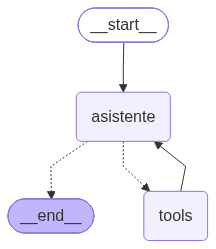

In [3]:
agente_pisa = construir_agente()

def config_hilo(thread_id: str, modelos: list[str] = None) -> dict:
    return {"configurable": {"thread_id": thread_id, "modelos": modelos or modelos_validados},
            "recursion_limit": LIMITE_RECURSION}

try:
    display(Image(agente_pisa.get_graph().draw_mermaid_png()))
except Exception:
    print("Additional dependencies required.")

# Prueba rápida en el notebook

In [4]:
def preguntar(pregunta: str, thread_id: str = "notebook", modelos: list[str] = None):
    """Lanza una pregunta, muestra la respuesta y los gráficos devueltos por las herramientas."""
    salida = agente_pisa.invoke({"messages": [("user", pregunta)]}, config=config_hilo(thread_id, modelos))
    for mensaje in salida["messages"]:
        if mensaje.type == "tool" and '"imagen"' in mensaje.content:
            display(Image(filename=str(resolver_imagen(json.loads(mensaje.content)["imagen"])), width=650))
    print(salida["messages"][-1].content)

preguntar("¿Rinden mejor en matemáticas los colegios rurales o los urbanos en 2022?")

[TOKENS openai/gpt-oss-120b] entrada=2285 salida=105 total=2390
   [1] get_fixed_strata_stats {'CNT': None, 'group_by': 'ubicacion', 'subject': 'math', 'year': 2022}
2026-10-30 21:02:53.498 No runtime found, using MemoryCacheStorageManager
[TOKENS openai/gpt-oss-120b] entrada=2450 salida=150 total=2600


En 2022, la media de puntuación en matemáticas de los colegios situados en áreas urbanas de la OCDE es de **481,5 puntos**, mientras que la de los colegios rurales es de **458,4 puntos**. Por lo tanto, los colegios urbanos rinden aproximadamente **23 puntos** más que los rurales. Esta diferencia refleja, en promedio, mayores recursos y entornos de aprendizaje más favorecedores en contextos urbanos dentro del conjunto de países de la OCDE.


# Conexión con Gradio

In [5]:
def responder_chat(mensaje, historial):
    config_ejecucion = config_hilo(f"sesion_gradio_{id(historial)}")
    yield "Analizando tu consulta..."

    for evento in agente_pisa.stream({"messages": [("user", mensaje)]}, config=config_ejecucion, stream_mode="updates"):
        for nodo, valor in evento.items():
            ultimo_msg = valor["messages"][-1]
            if getattr(ultimo_msg, "tool_calls", None):
                nombres = ", ".join(tc["name"] for tc in ultimo_msg.tool_calls)
                yield f"Consultando datos y modelos ({nombres})..."
            elif nodo == "tools":
                yield "Procesando resultados y redactando la conclusión..."

    estado = agente_pisa.get_state(config_ejecucion)
    yield estado.values["messages"][-1].content if estado and estado.values else "No se pudo recuperar la respuesta."

In [6]:
banco_ejemplos = [
    "¿Rinden mejor los colegios privados que los públicos en España?",
    "¿Cómo ha evolucionado la nota de los colegios rurales pequeños desde 2012?",
    "¿Qué nota sacan los alumnos con compromiso alto frente a los de compromiso bajo?",
    "Compara la nota media de los 12 países en 2022.",
    "¿Qué relación hay entre los recursos de estudio y la nota en matemáticas?",
    "¿Hay diferencias entre chicos y chicas en Corea del Sur?",
]

gr.ChatInterface(
    fn=responder_chat,
    title="Asistente PISA & Machine Learning",
    description="Asistente para el análisis de la nota en matemáticas de PISA 2012-2022 en 12 países",
    examples=random.sample(banco_ejemplos, 3),
).launch(inbrowser=True, inline=False, share=False)

HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
HTTP Request: HEAD https://huggingface.co/api/telemetry/https%3A/api.gradio.app/gradio-initiated-analytics "HTTP/1.1 200 OK"


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


HTTP Request: HEAD https://huggingface.co/api/telemetry/https%3A/api.gradio.app/gradio-launched-telemetry "HTTP/1.1 200 OK"
[TOKENS openai/gpt-oss-120b] entrada=2284 salida=148 total=2432
   [1] simulate_scenario {'CNT': 'ESP', 'modifications': {'gasto_alumno_secundaria_usd_ppp': 14000}, 'subject': 'math', 'year': 2022}
2026-10-30 21:03:09.849 No runtime found, using MemoryCacheStorageManager
2026-10-30 21:03:09.925 No runtime found, using MemoryCacheStorageManager
[TOKENS openai/gpt-oss-120b] entrada=2526 salida=256 total=2782


# Evaluación

In [7]:
# El evaluador crea un hilo nuevo por caso; los modelos se fijan con la cadena por defecto (MODELOS_GROQ_PRIORIDAD)
# Aviso: los casos de evaluador/reference_test.py son del bloque exploratorio de 33 países (ahora en anexo/)
# y hay que rehacerlos para la línea actual (ver REQUISITOS_PENDIENTES.md)
df_eval = ev.ejecutar_bateria_evaluacion(agente_pisa)

columnas_vista = [
    "ID", "Categoría", "Tools OK", "Fidelidad OK",
    "Estilo Limpio", "Calidad (1-5)", "Completitud (1-5)",
    "Tiempo (s)", "Tools Usadas", "Dictamen Juez"
]
display(df_eval[columnas_vista])

 Ejecutando caso :CS_Equidad_Social_Recursos_Espana_2022 -> ¿Cuál es la situación de España en 2022 respecto a la desigualdad social y la dotación de recursos en centros desfavorecidos en comparación con el resto de países analizados?


[TOKENS openai/gpt-oss-120b] entrada=2302 salida=436 total=2738
   [1] get_country_data {'CNT': 'ESP', 'variables': ['gini', 'gasto_alumno_secundaria_usd_ppp'], 'year': 2022}
[TOKENS openai/gpt-oss-120b] entrada=2385 salida=56 total=2441
   [1] get_cross_country_stats {'operation': 'mean', 'variable': 'gini', 'year': 2022}
[TOKENS openai/gpt-oss-120b] entrada=2454 salida=256 total=2710
   [1] get_cross_country_stats {'operation': 'mean', 'variable': 'gasto_alumno_secundaria_usd_ppp', 'year': 2022}
[TOKENS openai/gpt-oss-120b] entrada=2540 salida=352 total=2892


 Ejecutando caso :CS_Impacto_Desigualdad_y_Brecha_Recursos_Matematicas -> ¿Cómo se relacionan la desigualdad social y las brechas de recursos entre centros con el rendimiento en matemáticas en PISA? ¿Están sistemáticamente peor dotados los colegios desfavorecidos?


[TOKENS openai/gpt-oss-120b] entrada=2304 salida=569 total=2873
   [1] calculate_correlation {'variable_a': 'gini', 'variable_b': 'media_math_pais', 'year_a': 2022, 'year_b': 2022}
[TOKENS openai/gpt-oss-120b] entrada=2404 salida=104 total=2508
   [1] get_fixed_strata_stats {'CNT': None, 'group_by': 'tipo_centro', 'subject': 'math', 'year': 2022}
[TOKENS openai/gpt-oss-120b] entrada=2595 salida=591 total=3186


Error ejecutando CS_Impacto_Desigualdad_y_Brecha_Recursos_Matematicas: Error code: 429 - {'error': {'message': "Request too large for model `qwen/qwen3.8-27b` in organization `org_01m48n3m4ae4mv1n7z9xvgmgz3` service tier `on_demand` on output tokens per minute (OTPM): Limit 1000, Requested 1301. The request's expected output tokens exceed the enforced limit; reduce max_tokens (or the request's expected output) and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing", 'type': 'tokens', 'code': 'rate_limit_exceeded'}}
 Ejecutando caso :CS_Factores_Macroeconomicos_Rendimiento_Matematicas -> ¿Qué indicadores macroeconómicos y de desarrollo de un país se asocian más con un buen o mal rendimiento en matemáticas en PISA? ¿Influye la coyuntura económica de un año concreto?


Modelo openai/gpt-oss-120b no disponible (RateLimitError): se prueba el siguiente.
Respuesta generada con el modelo de respaldo openai/gpt-oss-20b
[TOKENS openai/gpt-oss-20b] entrada=2306 salida=1689 total=3995
   [1] get_cross_country_stats {'operation': 'mean', 'variable': 'media_math_pais', 'year': 2022}
Modelo openai/gpt-oss-120b no disponible (RateLimitError): se prueba el siguiente.
Respuesta generada con el modelo de respaldo openai/gpt-oss-20b
[TOKENS openai/gpt-oss-20b] entrada=2379 salida=369 total=2748
   [1] get_cross_variable_stats {'filter_value': 12000, 'filter_variable': 'gasto_alumno_secundaria_usd_ppp', 'metric': 'mean', 'operator': '>', 'target_variable': 'media_math_pais', 'year': 2022}
Modelo openai/gpt-oss-120b no disponible (RateLimitError): se prueba el siguiente.
Modelo openai/gpt-oss-20b no disponible (RateLimitError): se prueba el siguiente.


... (6 outputs left out)

Error ejecutando CS_Estabilidad_Temporal_y_Varianza_Presupuesto: Ningún modelo de Groq disponible ahora mismo (RateLimitError). Espera un minuto y vuelve a intentarlo.
 Ejecutando caso :CS_Inversion_Global_Esfuerzo_PIB_y_Factores_Rendimiento -> A nivel global en la OCDE, ¿qué se relaciona más con un alto rendimiento en matemáticas en PISA: el gasto real por alumno (desde preprimaria hasta secundaria) o el esfuerzo presupuestario en porcentaje del PIB? Además, según el modelo global, ¿qué peso real tienen el presupuesto y los salarios docentes frente al contexto socioeconómico?


Modelo openai/gpt-oss-120b no disponible (RateLimitError): se prueba el siguiente.
Respuesta generada con el modelo de respaldo openai/gpt-oss-20b
[TOKENS openai/gpt-oss-20b] entrada=2337 salida=825 total=3162
   [1] calculate_correlation {'variable_a': 'gasto_alumno_secundaria_usd_ppp', 'variable_b': 'media_math_pais', 'year_a': 2022, 'year_b': 2022}
Modelo openai/gpt-oss-120b no disponible (RateLimitError): se prueba el siguiente.
Modelo openai/gpt-oss-20b no disponible (RateLimitError): se prueba el siguiente.


Error ejecutando CS_Inversion_Global_Esfuerzo_PIB_y_Factores_Rendimiento: Ningún modelo de Groq disponible ahora mismo (RateLimitError). Espera un minuto y vuelve a intentarlo.

Evaluación finalizada.


,ID,Categoría,Tools OK,Fidelidad OK,Estilo Limpio,Calidad (1-5),Completitud (1-5),Tiempo (s),Tools Usadas,Dictamen Juez
0,CS_Equidad_Social_Recursos_Espana_2022,General,FALLO,FALLO,OK,1,1,3.0,"get_country_data, get_cross_country_stats, get...",El agente inventa datos ajenos a la referencia...
1,CS_Impacto_Desigualdad_y_Brecha_Recursos_Matem...,General,ERROR,ERROR,-,0,0,0.0,Error en ejecución,"Error code: 429 - {'error': {'message': ""Reque..."
2,CS_Factores_Macroeconomicos_Rendimiento_Matema...,General,ERROR,ERROR,-,0,0,0.0,Error en ejecución,Ningún modelo de Groq disponible ahora mismo (...
3,CS_Perfiles_Macro_Desempleo_y_Estructura_Produ...,General,ERROR,ERROR,-,0,0,0.0,Error en ejecución,Ningún modelo de Groq disponible ahora mismo (...
4,CS_Presupuesto_Renta_y_Simulacion_Espana,General,ERROR,ERROR,-,0,0,0.0,Error en ejecución,Ningún modelo de Groq disponible ahora mismo (...
5,CS_Estabilidad_Temporal_y_Varianza_Presupuesto,General,ERROR,ERROR,-,0,0,0.0,Error en ejecución,Ningún modelo de Groq disponible ahora mismo (...
6,CS_Inversion_Global_Esfuerzo_PIB_y_Factores_Re...,General,ERROR,ERROR,-,0,0,0.0,Error en ejecución,Ningún modelo de Groq disponible ahora mismo (...


In [ ]:
for _, fila in df_eval.iterrows():
    print(f"=== {fila['ID']} ({fila['Calidad (1-5)']}/5) ===")
    print(f"Respuesta:{fila['Dictamen Juez']}


SyntaxError: unterminated f-string literal (detected at line 3) (1121543115.py, line 3)